In [2]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import chess

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out, inplace=True)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + residual
        out = F.relu(out, inplace=True)
        return out

class AlphaZeroResNet(nn.Module):
    def __init__(
        self,
        input_channels=12,
        num_blocks=12,
        channels=128,
        policy_size=4864,
        value_hidden=256,
        value_dropout=0.15,
    ):
        super().__init__()

        self.input_conv = nn.Conv2d(input_channels, channels, kernel_size=3, padding=1, bias=False)
        self.input_bn = nn.BatchNorm2d(channels)

        self.res_tower = nn.Sequential(*[ResidualBlock(channels) for _ in range(num_blocks)])

        self.policy_conv = nn.Conv2d(channels, 32, kernel_size=1, bias=False)
        self.policy_bn = nn.BatchNorm2d(32)
        self.policy_fc = nn.Linear(32 * 8 * 8, policy_size)

        self.value_conv = nn.Conv2d(channels, 3, kernel_size=1, bias=False)
        self.value_bn = nn.BatchNorm2d(3)
        self.value_fc1 = nn.Linear(3 * 8 * 8, value_hidden)
        self.value_dropout = nn.Dropout(value_dropout)
        self.value_fc2 = nn.Linear(value_hidden, 1)

    def forward(self, x):
        x = self.input_conv(x)
        x = self.input_bn(x)
        x = F.relu(x, inplace=True)

        x = self.res_tower(x)

        p = self.policy_conv(x)
        p = self.policy_bn(p)
        p = F.relu(p, inplace=True)
        p = p.view(p.size(0), -1)
        policy_logits = self.policy_fc(p)

        v = self.value_conv(x)
        v = self.value_bn(v)
        v = F.relu(v, inplace=True)
        v = v.view(v.size(0), -1)
        v = self.value_fc1(v)
        v = F.relu(v, inplace=True)
        v = self.value_dropout(v)
        value = torch.tanh(self.value_fc2(v)).squeeze(1)

        return policy_logits, value

In [5]:
class ResBlock(nn.Module):
    def __init__(self, channels):
        super(ResBlock, self).__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x 
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual 
        out = F.relu(out)
        return out

# 2. The DUAL-HEAD Chess Neural Network
class ChessResNet(nn.Module):
    def __init__(self, num_blocks=10, hidden_channels=128):
        super(ChessResNet, self).__init__()
        
        self.start_conv = nn.Conv2d(12, hidden_channels, kernel_size=3, padding=1)
        self.start_bn = nn.BatchNorm2d(hidden_channels)
        self.res_blocks = nn.ModuleList([ResBlock(hidden_channels) for _ in range(num_blocks)])
        
        # --- FIXED POLICY HEAD (76 Planes) ---
        self.policy_conv = nn.Conv2d(hidden_channels, 76, kernel_size=1) 
        self.policy_bn = nn.BatchNorm2d(76)
        
        # 76 planes * 8 * 8 squares = 4864 nodes
        self.policy_fc = nn.Linear(76 * 8 * 8, 4864) 
        
        # --- Value Head ---
        self.eval_conv = nn.Conv2d(hidden_channels, 1, kernel_size=1)
        self.eval_bn = nn.BatchNorm2d(1)
        self.eval_fc1 = nn.Linear(8 * 8, 64) 
        self.eval_fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = F.relu(self.start_bn(self.start_conv(x)))
        for block in self.res_blocks:
            x = block(x)
            
        # Policy output
        p = F.relu(self.policy_bn(self.policy_conv(x)))
        p = p.view(-1, 4864) # Flatten to the correct 4864 size
        policy_out = self.policy_fc(p) 
        
        # Value output
        v = F.relu(self.eval_bn(self.eval_conv(x)))
        v = v.view(-1, 64) 
        v = F.relu(self.eval_fc1(v))
        v = self.eval_fc2(v)
        value_out = torch.tanh(v) 
        
        return policy_out, value_out

In [6]:
other_model = ChessResNet().to(DEVICE)

ckpt = torch.load(
    r"C:\Users\abdal\OneDrive\Desktop\chess-project\blackie\final_chess_resnet.pth",
    map_location=DEVICE
)

other_model.load_state_dict(ckpt)
other_model.eval()

ChessResNet(
  (start_conv): Conv2d(12, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (start_bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (res_blocks): ModuleList(
    (0-9): 10 x ResBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (policy_conv): Conv2d(128, 76, kernel_size=(1, 1), stride=(1, 1))
  (policy_bn): BatchNorm2d(76, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (policy_fc): Linear(in_features=4864, out_features=4864, bias=True)
  (eval_conv): Conv2d(128, 1, kernel_size=(1, 1), stride=(1, 1))
  (eval_bn): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

In [7]:
model = AlphaZeroResNet(
    input_channels=12,
    num_blocks=12,
    channels=128,
    policy_size=4864,
).to(DEVICE)

checkpoint = torch.load(r"C:\Users\abdal\OneDrive\Desktop\chess-project\ver1.3\chess ver1.3.pth", map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [8]:
import numpy as np
import chess

def board_to_tensor(board):
    tensor = np.zeros((12, 64), dtype=np.float32)

    for sq, piece in board.piece_map().items():
        layer = (piece.piece_type - 1) + (0 if piece.color == chess.WHITE else 6)
        tensor[layer][sq] = 1.0

    tensor = tensor.reshape(12, 8, 8)
    return np.flip(tensor, axis=1).copy()

In [9]:
def move_to_index(move):
    from_sq = move.from_square
    to_sq = move.to_square

    r0, c0 = divmod(from_sq, 8)
    r1, c1 = divmod(to_sq, 8)

    dr = r1 - r0
    dc = c1 - c0

    knight_moves = [
        (2, 1), (1, 2), (-1, 2), (-2, 1),
        (-2, -1), (-1, -2), (1, -2), (2, -1)
    ]

    if (dr, dc) in knight_moves:
        plane = 56 + knight_moves.index((dr, dc))
        return plane * 64 + from_sq

    if move.promotion is not None:
        if dc == 0:
            dir_idx = 0
        elif dc == -1:
            dir_idx = 1
        else:
            dir_idx = 2

        promo_map = {
            chess.KNIGHT: 0,
            chess.BISHOP: 1,
            chess.ROOK: 2,
            chess.QUEEN: 3
        }

        piece_idx = promo_map[move.promotion]
        plane = 64 + dir_idx * 4 + piece_idx
        return plane * 64 + from_sq

    directions = [
        (1, 0), (1, 1), (0, 1), (-1, 1),
        (-1, 0), (-1, -1), (0, -1), (1, -1)
    ]

    for dir_idx, (drd, dcd) in enumerate(directions):
        for dist in range(1, 8):
            if dr == drd * dist and dc == dcd * dist:
                plane = dir_idx * 7 + (dist - 1)
                return plane * 64 + from_sq

    raise ValueError(f"Could not encode move: {move.uci()}")

In [10]:
def prepare_model_input(board: chess.Board):
    is_black = (board.turn == chess.BLACK)
    eval_board = board.mirror() if is_black else board
    x = board_to_tensor(eval_board).astype(np.float32)
    return x, is_black

def mirror_move_if_needed(move: chess.Move, is_black: bool):
    if not is_black:
        return move
    return chess.Move(
        chess.square_mirror(move.from_square),
        chess.square_mirror(move.to_square),
        move.promotion
    )

In [11]:
# =========================================================
# REQUIRED: you must already have these
# =========================================================
# 1) model
# 2) DEVICE
# 3) board_to_tensor(board) -> np.ndarray shape (12, 8, 8)
# 4) move_to_index(move) -> int in [0, 4863]
#
# IMPORTANT:
# board_to_tensor and move_to_index must match training/inference exactly.
# =========================================================


# =========================================================
# DIRICHLET NOISE
# =========================================================
def add_dirichlet_noise(priors, alpha=0.3, epsilon=0.25):
    """
    priors: numpy array of probabilities over legal moves
    """
    noise = np.random.dirichlet([alpha] * len(priors))
    return (1 - epsilon) * priors + epsilon * noise


# =========================================================
# TERMINAL VALUE
# =========================================================
def terminal_value(board):
    result = board.result()

    if result == "1-0":
        return 1.0 if board.turn == chess.WHITE else -1.0
    elif result == "0-1":
        return 1.0 if board.turn == chess.BLACK else -1.0
    else:
        return 0.0


# =========================================================
# NODE
# =========================================================
class MCTSNode:
    def __init__(self, board, parent=None, prior=0.0, move=None):
        self.board = board
        self.parent = parent
        self.prior = prior
        self.move = move

        self.children = {}   # move -> child node
        self.visit_count = 0
        self.value_sum = 0.0
        self.is_expanded = False

    @property
    def q_value(self):
        if self.visit_count == 0:
            return 0.0
        return self.value_sum / self.visit_count


# =========================================================
# PUCT
# =========================================================
def puct_score(parent, child, c_puct=1.5):
    q = -child.q_value
    parent_visits = max(1, parent.visit_count)
    u = c_puct * child.prior * math.sqrt(parent_visits) / (1 + child.visit_count)
    return q + u


def select_child(node, c_puct=1.5):
    best_move = None
    best_child = None
    best_score = -float("inf")

    for move, child in node.children.items():
        score = puct_score(node, child, c_puct)
        if score > best_score:
            best_score = score
            best_move = move
            best_child = child

    return best_move, best_child


# =========================================================
# EXPAND NODE
# =========================================================
def expand_node(
    node,
    model,
    device,
    policy_size=4864,
    add_noise=False,
    dirichlet_alpha=0.3,
    dirichlet_epsilon=0.25
):
    board = node.board

    if board.is_game_over() or board.can_claim_draw():
        node.is_expanded = True
        return float(terminal_value(board))

    x_np, is_black = prepare_model_input(board)
    x = torch.tensor(x_np, dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        policy_logits, value = model(x)
        policy_logits = policy_logits[0]
        value = float(value.item())

    legal_moves = list(board.legal_moves)

    legal_indices = []
    filtered_moves = []

    for move in legal_moves:
        try:
            enc_move = mirror_move_if_needed(move, is_black)
            idx = move_to_index(enc_move)
            if 0 <= idx < policy_size:
                legal_indices.append(idx)
                filtered_moves.append(move)
        except Exception:
            continue

    if len(filtered_moves) == 0:
        node.is_expanded = True
        return value

    legal_logits = policy_logits[legal_indices]
    legal_probs = F.softmax(legal_logits, dim=0).cpu().numpy()

    if add_noise:
        legal_probs = add_dirichlet_noise(
            legal_probs,
            alpha=dirichlet_alpha,
            epsilon=dirichlet_epsilon
        )

    for move, prob in zip(filtered_moves, legal_probs):
        next_board = board.copy()
        next_board.push(move)
        node.children[move] = MCTSNode(
            board=next_board,
            parent=node,
            prior=float(prob),
            move=move
        )

    node.is_expanded = True
    return value


# =========================================================
# BACKUP
# =========================================================
def backup(search_path, value):
    if value is None:
        value = 0.0

    value = float(value)

    for node in reversed(search_path):
        node.visit_count += 1
        node.value_sum += value
        value = -value


# =========================================================
# RUN MCTS
# =========================================================
def run_mcts(
    root_board,
    model,
    device,
    num_simulations=100,
    c_puct=1.5,
    policy_size=4864,
    add_root_noise=True,
    dirichlet_alpha=0.3,
    dirichlet_epsilon=0.25
):
    root = MCTSNode(root_board.copy())

    # Expand root once with optional Dirichlet noise
    expand_node(
        root,
        model,
        device,
        policy_size=policy_size,
        add_noise=add_root_noise,
        dirichlet_alpha=dirichlet_alpha,
        dirichlet_epsilon=dirichlet_epsilon
    )

    for _ in range(num_simulations):
        node = root
        search_path = [node]

        # Selection
        while node.is_expanded and node.children:
            _, node = select_child(node, c_puct=c_puct)
            search_path.append(node)

        # Expansion + evaluation
        value = expand_node(
            node,
            model,
            device,
            policy_size=policy_size,
            add_noise=False
        )

        # Backup
        backup(search_path, value)

    return root


# =========================================================
# VISIT COUNTS -> POLICY TARGET
# =========================================================
def get_policy_target_from_root(root, policy_size=4864, temperature=1.0):
    move_visits = []
    legal_moves = []

    for move, child in root.children.items():
        legal_moves.append(move)
        move_visits.append(child.visit_count)

    move_visits = np.array(move_visits, dtype=np.float32)

    if temperature <= 1e-6:
        probs = np.zeros_like(move_visits, dtype=np.float32)
        probs[np.argmax(move_visits)] = 1.0
    else:
        adjusted = move_visits ** (1.0 / temperature)
        probs = adjusted / adjusted.sum()

    full_policy = np.zeros(policy_size, dtype=np.float32)

    is_black = (root.board.turn == chess.BLACK)

    for move, prob in zip(legal_moves, probs):
        enc_move = mirror_move_if_needed(move, is_black)
        idx = move_to_index(enc_move)
        full_policy[idx] = prob

    return full_policy, legal_moves, probs


# =========================================================
# CHOOSE MOVE FROM ROOT
# =========================================================
def sample_move_from_root(root, temperature=1.0):
    legal_moves = []
    move_visits = []

    for move, child in root.children.items():
        legal_moves.append(move)
        move_visits.append(child.visit_count)

    move_visits = np.array(move_visits, dtype=np.float32)

    if temperature <= 1e-6:
        return legal_moves[int(np.argmax(move_visits))]

    adjusted = move_visits ** (1.0 / temperature)
    probs = adjusted / adjusted.sum()
    idx = np.random.choice(len(legal_moves), p=probs)
    return legal_moves[idx]


# =========================================================
# SELF-PLAY ONE GAME
# =========================================================
def self_play_game(
    model,
    device,
    num_simulations=100,
    c_puct=1.5,
    policy_size=4864,
    max_moves=300,
    opening_temperature_moves=15,
    opening_temperature=0.7,
    later_temperature=0.0,
    dirichlet_alpha=0.3,
    dirichlet_epsilon=0.25
):
    model.eval()
    board = chess.Board()

    # store (state, policy_target, player_color)
    game_history = []

    move_number = 0

    while not board.is_game_over() and not board.can_claim_draw() and move_number < max_moves:
        root = run_mcts(
            root_board=board,
            model=model,
            device=device,
            num_simulations=num_simulations,
            c_puct=c_puct,
            policy_size=policy_size,
            add_root_noise=True,
            dirichlet_alpha=dirichlet_alpha,
            dirichlet_epsilon=dirichlet_epsilon
        )

        temperature = opening_temperature if move_number < opening_temperature_moves else later_temperature

        policy_target, legal_moves, visit_probs = get_policy_target_from_root(
            root,
            policy_size=policy_size,
            temperature=temperature
        )

        state, is_black = prepare_model_input(board)
        player_to_move = board.turn
        game_history.append((state, policy_target, player_to_move))

        chosen_move = sample_move_from_root(root, temperature=temperature)
        board.push(chosen_move)

        move_number += 1

    # Final result from White perspective
    result = board.result()
    if result == "1-0":
        white_outcome = 1.0
    elif result == "0-1":
        white_outcome = -1.0
    else:
        white_outcome = 0.0

    # Assign values per stored state from side-to-move perspective
    features = []
    policy_targets = []
    value_targets = []

    for state, policy_target, player_to_move in game_history:
        value = white_outcome if player_to_move == chess.WHITE else -white_outcome

        features.append(state)
        policy_targets.append(policy_target)
        value_targets.append(value)

    features = np.array(features, dtype=np.float32)
    policy_targets = np.array(policy_targets, dtype=np.float32)
    value_targets = np.array(value_targets, dtype=np.float32)

    return features, policy_targets, value_targets, result


# =========================================================
# GENERATE MANY SELF-PLAY GAMES
# =========================================================
def generate_self_play_dataset(
    model,
    device,
    num_games=10,
    num_simulations=100,
    c_puct=1.5,
    policy_size=4864,
    save_path="self_play_data.npz"
):
    all_features = []
    all_policy_targets = []
    all_value_targets = []
    results = {"1-0": 0, "0-1": 0, "1/2-1/2": 0, "*": 0}

    for game_idx in range(num_games):
        features, policy_targets, value_targets, result = self_play_game(
            model=model,
            device=device,
            num_simulations=num_simulations,
            c_puct=c_puct,
            policy_size=policy_size
        )

        all_features.append(features)
        all_policy_targets.append(policy_targets)
        all_value_targets.append(value_targets)

        results[result] += 1

        print(
            f"Game {game_idx+1}/{num_games} | "
            f"result={result} | "
            f"positions={len(features)}"
        )

    all_features = np.concatenate(all_features, axis=0)
    all_policy_targets = np.concatenate(all_policy_targets, axis=0)
    all_value_targets = np.concatenate(all_value_targets, axis=0)

    np.savez_compressed(
        save_path,
        features=all_features,
        policy_targets=all_policy_targets,
        value_targets=all_value_targets
    )

    print("\nSaved self-play dataset:")
    print(" features:", all_features.shape)
    print(" policy_targets:", all_policy_targets.shape)
    print(" value_targets:", all_value_targets.shape)
    print(" results:", results)
    print(" path:", save_path)

In [12]:
def choose_move_with_mcts(
    board,
    model,
    device,
    num_simulations=200,
    c_puct=1.5,
    policy_size=4864,
    temperature=0.0,
    dirichlet_alpha=0.3,
    dirichlet_epsilon=0.0,
    add_root_noise=False,
    return_debug=False
):
    root = MCTSNode(board.copy())

    root_value = expand_node(
        root,
        model=model,
        device=device,
        policy_size=policy_size,
        add_noise=add_root_noise,
        dirichlet_alpha=dirichlet_alpha,
        dirichlet_epsilon=dirichlet_epsilon
    )

    for _ in range(num_simulations):
        node = root
        search_path = [node]

        while node.is_expanded and node.children:
            best_move = None
            best_child = None
            best_score = -float("inf")

            for move, child in node.children.items():
                score = puct_score(node, child, c_puct=c_puct)
                if score > best_score:
                    best_score = score
                    best_move = move
                    best_child = child

            node = best_child
            search_path.append(node)

        if node.board.is_game_over() or node.board.can_claim_draw():
            value = float(terminal_value(node.board))
        else:
            value = expand_node(
                node,
                model=model,
                device=device,
                policy_size=policy_size,
                add_noise=False
            )

        backup(search_path, value)

    move_visits = []
    legal_moves = []

    for move, child in root.children.items():
        legal_moves.append(move)
        move_visits.append(child.visit_count)

    move_visits = np.array(move_visits, dtype=np.float32)

    if len(legal_moves) == 0:
        if return_debug:
            return None, root, {
                "root_value": root_value,
                "top_moves": []
            }
        return None, root

    if temperature <= 1e-8:
        best_idx = int(np.argmax(move_visits))
        chosen_move = legal_moves[best_idx]
    else:
        adjusted = move_visits ** (1.0 / temperature)
        probs = adjusted / adjusted.sum()
        chosen_move = np.random.choice(legal_moves, p=probs)

    debug_info = None
    if return_debug:
        scored_moves = []
        for move, child in root.children.items():
            parent_visits = max(1, root.visit_count)
            u = c_puct * child.prior * math.sqrt(parent_visits) / (1 + child.visit_count)
            q_from_parent = -child.q_value
            score = q_from_parent + u

            scored_moves.append({
                "move": move.uci(),
                "visits": child.visit_count,
                "prior": float(child.prior),
                "q_from_child": float(child.q_value),
                "q_from_parent": float(q_from_parent),
                "u": float(u),
                "puct": float(score)
            })

        scored_moves.sort(key=lambda x: x["visits"], reverse=True)

        debug_info = {
            "root_value": float(root_value),
            "chosen_move": chosen_move.uci(),
            "top_moves": scored_moves[:10]
        }

        return chosen_move, root, debug_info

    return chosen_move, root

def get_best_move(
    board,
    model,
    device,
    depth=3,
    num_simulations=None,
    resign_threshold=-0.95,
    c_puct=1.5,
    policy_size=4864
):
    if num_simulations is None:
        num_simulations = max(50, depth * 50)

    chosen_move, root, debug = choose_move_with_mcts(
        board=board,
        model=model,
        device=device,
        num_simulations=num_simulations,
        c_puct=c_puct,
        policy_size=policy_size,
        temperature=0.0,
        return_debug=True
    )

    scored_moves = []
    if debug and 'top_moves' in debug:
        for item in debug['top_moves']:
            mv = chess.Move.from_uci(item['move'])
            scored_moves.append((mv, item['puct'], item['visits'] / max(1, root.visit_count)))

    best_eval = debug['root_value'] if debug else 0.0
    resigned = (best_eval < resign_threshold) and (root.visit_count > 20)

    return chosen_move, best_eval, scored_moves, resigned


In [13]:
def play_model_vs_model_traced(
    white_model,
    black_model,
    device,
    white_name="WhiteModel",
    black_name="BlackModel",
    white_sims=200,
    black_sims=200,
    c_puct=1.5,
    max_moves=300,
    white_temperature=0.0,
    black_temperature=0.0,
    white_dirichlet_epsilon=0.0,
    black_dirichlet_epsilon=0.0,
    pause_seconds=0.0,
    show_board=True
):
    board = chess.Board()
    move_count = 0
    trace = []

    while not board.is_game_over() and not board.can_claim_draw() and move_count < max_moves:
        if show_board:
            clear_output(wait=True)
            display(SVG(chess.svg.board(board=board, size=500)))
            print(f"Move {move_count + 1}")
            print("Turn:", "White" if board.turn == chess.WHITE else "Black")
            print("FEN:", board.fen())

        if board.turn == chess.WHITE:
            move, root, debug = choose_move_with_mcts(
                board=board,
                model=white_model,
                device=device,
                num_simulations=white_sims,
                c_puct=c_puct,
                temperature=white_temperature,
                dirichlet_epsilon=white_dirichlet_epsilon,
                add_root_noise=(white_dirichlet_epsilon > 0),
                return_debug=True
            )
            model_name = white_name
        else:
            move, root, debug = choose_move_with_mcts(
                board=board,
                model=black_model,
                device=device,
                num_simulations=black_sims,
                c_puct=c_puct,
                temperature=black_temperature,
                dirichlet_epsilon=black_dirichlet_epsilon,
                add_root_noise=(black_dirichlet_epsilon > 0),
                return_debug=True
            )
            model_name = black_name

        if move is None:
            break

        trace_entry = {
            "move_number": move_count + 1,
            "side": "White" if board.turn == chess.WHITE else "Black",
            "model": model_name,
            "fen_before": board.fen(),
            "chosen_move": move.uci(),
            "root_value": debug["root_value"],
            "top_moves": debug["top_moves"]
        }
        trace.append(trace_entry)

        if show_board:
            print(f"Chosen by {model_name}: {move.uci()}")
            print(f"Root value: {debug['root_value']:.4f}")
            print("Top candidates:")
            for item in debug["top_moves"][:5]:
                print(
                    f"  {item['move']:6s} | visits={item['visits']:4d} "
                    f"| prior={item['prior']:.4f} | q_parent={item['q_from_parent']:.4f} "
                    f"| u={item['u']:.4f} | puct={item['puct']:.4f}"
                )

        board.push(move)
        move_count += 1

        if pause_seconds > 0:
            time.sleep(pause_seconds)

    if show_board:
        clear_output(wait=True)
        display(SVG(chess.svg.board(board=board, size=500)))
        print("Game Over")
        print("Result:", board.result() if board.is_game_over() else "1/2-1/2 or stopped")

    result = board.result() if board.is_game_over() else "1/2-1/2"
    return board, result, trace

In [14]:
import chess.svg
from IPython.display import display, SVG, clear_output
import time

def play_self_game_svg(
    model,
    device,
    num_simulations=50,
    c_puct=1.5,
    policy_size=4864,
    max_moves=200,
    opening_temperature_moves=12,
    opening_temperature=1.0,
    later_temperature=0.0,
    dirichlet_alpha=0.2,
    dirichlet_epsilon=0.15,
    pause_seconds=1.0
):
    model.eval()
    board = chess.Board()
    move_number = 0

    while not board.is_game_over() and not board.can_claim_draw() and move_number < max_moves:
        clear_output(wait=True)
        display(SVG(chess.svg.board(board=board, size=400)))

        root = run_mcts(
            root_board=board,
            model=model,
            device=device,
            num_simulations=num_simulations,
            c_puct=c_puct,
            policy_size=policy_size,
            add_root_noise=True,
            dirichlet_alpha=dirichlet_alpha,
            dirichlet_epsilon=dirichlet_epsilon
        )

        temperature = opening_temperature if move_number < opening_temperature_moves else later_temperature
        chosen_move = sample_move_from_root(root, temperature=temperature)

        side = "White" if board.turn == chess.WHITE else "Black"
        print(f"Move {move_number + 1}: {side} plays {board.san(chosen_move)} ({chosen_move.uci()})")

        board.push(chosen_move)
        move_number += 1
        time.sleep(pause_seconds)

    clear_output(wait=True)
    display(SVG(chess.svg.board(board=board, size=400)))

    result = board.result()
    if result == "*":
        result = "1/2-1/2"

    print("Game finished.")
    print("Result:", result)
    return board, result

In [15]:
import time
import chess
import chess.svg
from IPython.display import display, SVG, clear_output

def render_board(board, last_move=None, size=420):
    display(SVG(chess.svg.board(board=board, lastmove=last_move, size=size)))


def play_against_model(
    model,
    device,
    human_color="white",
    depth=3,
    resign_threshold=-0.95,
    board_size=420,
    wait_after_model_move=True
):
    board = chess.Board()
    move_history = []

    human_color = human_color.lower().strip()
    human_is_white = (human_color == "white")

    while True:
        clear_output(wait=True)
        last_move = move_history[-1] if move_history else None
        render_board(board, last_move=last_move, size=board_size)

        print("FEN:", board.fen())
        print("-" * 70)

        if board.is_game_over(claim_draw=True):
            outcome = board.outcome(claim_draw=True)
            print("Game over.")
            print("Result:", board.result(claim_draw=True))
            if outcome is not None:
                print("Winner:", outcome.winner)
            print("Moves:", " ".join(m.uci() for m in move_history))
            break

        human_turn = (board.turn == chess.WHITE and human_is_white) or (
            board.turn == chess.BLACK and not human_is_white
        )

        if human_turn:
            print("Your turn.")
            print("Enter SAN like e4 or Nf3, or UCI like e2e4.")
            print("Type 'legal' to list legal moves.")
            print("Type 'resign' or 'quit' to end.")

            while True:
                user_text = input("Your move: ").strip()

                if user_text.lower() in ["quit", "resign", "exit"]:
                    print("You resigned.")
                    return board

                if user_text.lower() == "legal":
                    print([m.uci() for m in board.legal_moves])
                    continue

                move = None
                try:
                    move = board.parse_san(user_text)
                except Exception:
                    try:
                        move = chess.Move.from_uci(user_text.lower())
                        if move not in board.legal_moves:
                            move = None
                    except Exception:
                        move = None

                if move is None:
                    print("Invalid or illegal move. Try again.")
                    continue

                print(f"You played: {board.san(move)} ({move.uci()})")
                board.push(move)
                move_history.append(move)
                break

        else:
            side = "White" if board.turn == chess.WHITE else "Black"
            print(f"Model ({side}) thinking... depth={depth}")

            best_move, best_eval, scored_moves, resigned = get_best_move(
                board=board,
                model=model,
                device=device,
                depth=depth,
                resign_threshold=resign_threshold
            )

            print("\nAll legal moves by policy:")
            for i, (mv, logit, prob) in enumerate(scored_moves, start=1):
                san = board.san(mv)
                print(f"{i:2d}. {san:8s} ({mv.uci()}) | logit={logit:8.4f} | prob={prob:.4f}")

            if resigned:
                print("\nModel resigns.")
                return board

            if best_move is None:
                print("\nModel found no move and resigns.")
                return board

            chosen_san = board.san(best_move)
            print(f"\nChosen move: {chosen_san} ({best_move.uci()})")
            print(f"Search eval: {best_eval:+.4f}")

            if wait_after_model_move:
                input("\nPress Enter to make the model play this move...")

            board.push(best_move)
            move_history.append(best_move)

            clear_output(wait=True)
            render_board(board, last_move=best_move, size=board_size)
            print(f"Model played: {chosen_san} ({best_move.uci()})")
            print(f"Search eval: {best_eval:+.4f}")

            if wait_after_model_move:
                input("\nPress Enter to continue...")
            else:
                time.sleep(1.5)

    return board

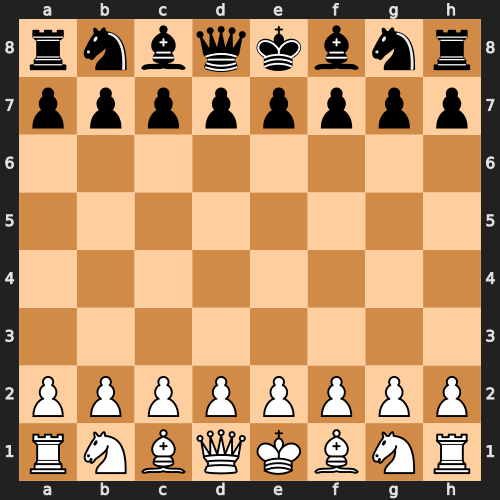

Move 1
Turn: White
FEN: rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1


AttributeError: module 'numpy' has no attribute 's_'

In [16]:
final_board, result, trace = play_model_vs_model_traced(
    white_model=model,
    black_model=other_model,
    white_name="AlphaZeroResNet_v1.4",
    black_name="ChessResNet_blackie",
    device=DEVICE,
    white_sims=200,
    black_sims=200,
    white_temperature=0.0,
    black_temperature=0.0,
    white_dirichlet_epsilon=0.0,
    black_dirichlet_epsilon=0.0,
    max_moves=300,
    pause_seconds=4,
    show_board=True
)

print("Final result:", result)

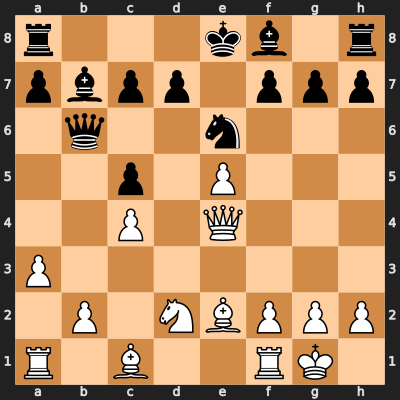

KeyboardInterrupt: 

In [ ]:
final_board, result = play_self_game_svg(
    model=model,
    device=DEVICE,
    num_simulations=400,
    c_puct=1.2,
    policy_size=4864,
    max_moves=200,
    opening_temperature_moves=0,
    opening_temperature=0.0,
    later_temperature=0.0,
    dirichlet_alpha=0.3,
    dirichlet_epsilon=0.0,
    pause_seconds=0.00001
)

In [ ]:
print("hello world")
X = input("Enter something: ")
print("You entered:", X)

hello world
You entered: 55555
